# Next Word Prediction & Text Generation using RNN and LSTM

# 1: Setup and Dataset Exploration

### 1.1 Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import pickle
import json
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

### 1.2 Load Dataset

In [2]:
df = pd.read_csv("data/qoute_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (3038, 2)


,quote,Author
0,“The world as we have created it is a process ...,Albert Einstein
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling
2,“There are only two ways to live your life. On...,Albert Einstein
3,"“The person, be it gentleman or lady, who has ...",Jane Austen
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe


# 2 Data Preprocessing 

In [3]:
quotes = df['quote']
quotes = quotes.str.lower()

translator = str.maketrans('', '', string.punctuation)
quotes = quotes.apply(lambda x: x.translate(translator))

In [4]:
quotes.head()

0    “the world as we have created it is a process ...
1    “it is our choices harry that show what we tru...
2    “there are only two ways to live your life one...
3    “the person be it gentleman or lady who has no...
4    “imperfection is beauty madness is genius and ...
Name: quote, dtype: str

### 2.1 Tokenization

In [5]:
vocab_size = 8978

tokinizer = Tokenizer(num_words=vocab_size)
tokinizer.fit_on_texts(quotes)
     

word_index = tokinizer.word_index
print(len(word_index))
list(word_index.items())[:10]

8978


[('the', 1),
 ('you', 2),
 ('to', 3),
 ('and', 4),
 ('a', 5),
 ('i', 6),
 ('is', 7),
 ('of', 8),
 ('that', 9),
 ('it', 10)]

In [6]:
sequence = tokinizer.texts_to_sequences(quotes)

In [7]:
quotes[0]

'“the world as we have created it is a process of our thinking it cannot be changed without changing our thinking”'

In [8]:
sequence[0]

[713,
 62,
 29,
 19,
 16,
 946,
 10,
 7,
 5,
 1156,
 8,
 70,
 293,
 10,
 145,
 12,
 809,
 104,
 752,
 70,
 2461]

In [9]:
X = []
y = []

for seq in sequence:
    for i in range(1, len(seq)):
        input_seq = seq[:i]
        output_seq = seq[i]

        X.append(input_seq)
        y.append(output_seq)

### 2.2 Padding

In [11]:


max_len = 100

X_padded = pad_sequences(
    X,
    maxlen=max_len,
    padding='pre',
    truncating='pre'
)

print("X shape:", X_padded.shape)

X shape: (85270, 100)


In [12]:
y = np.array(y)

### 2.3 One-Hot Encoding

In [13]:
from tensorflow.keras.utils import to_categorical
y_one_hot = to_categorical(
    y,
    num_classes=vocab_size
)

# 3. Building RNN Model

In [14]:
embedding_dim = 32

rnn_units = 64

In [15]:
rnn_model = Sequential()

rnn_model.add(
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        input_length=max_len
    )
)

rnn_model.add(
    SimpleRNN(units=rnn_units)
)

rnn_model.add(
    Dense(
        units=vocab_size,
        activation='softmax'
    )
)

/opt/anaconda3/envs/deep-learning/lib/python3.11/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [16]:
rnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [17]:
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

# 4. Building LSTM Model

In [18]:
lstm_model = Sequential()
lstm_model.add(
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_len)
)
lstm_model.add(LSTM(units=rnn_units))
lstm_model.add(Dense(units=vocab_size, activation='softmax'))
     

lstm_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
     

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

# 5. Train LSTM

In [22]:
epochs = 50
batch_size = 16

In [23]:
history_lstm = lstm_model.fit(
    X_padded,
    y_one_hot,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.1
)

Epoch 1/50
4797/4797 ━━━━━━━━━━━━━━━━━━━━ 79s 16ms/step - accuracy: 0.1059 - loss: 5.7013 - val_accuracy: 0.1028 - val_loss: 6.5097
Epoch 2/50
4797/4797 ━━━━━━━━━━━━━━━━━━━━ 75s 16ms/step - accuracy: 0.1203 - loss: 5.4189 - val_accuracy: 0.1070 - val_loss: 6.5708
Epoch 3/50
4797/4797 ━━━━━━━━━━━━━━━━━━━━ 76s 16ms/step - accuracy: 0.1360 - loss: 5.1548 - val_accuracy: 0.1146 - val_loss: 6.6432
Epoch 4/50
4797/4797 ━━━━━━━━━━━━━━━━━━━━ 74s 15ms/step - accuracy: 0.1499 - loss: 4.9193 - val_accuracy: 0.1141 - val_loss: 6.7116
Epoch 5/50
4797/4797 ━━━━━━━━━━━━━━━━━━━━ 75s 16ms/step - accuracy: 0.1640 - loss: 4.7124 - val_accuracy: 0.1162 - val_loss: 6.7897
Epoch 6/50
4797/4797 ━━━━━━━━━━━━━━━━━━━━ 77s 16ms/step - accuracy: 0.1790 - loss: 4.5238 - val_accuracy: 0.1152 - val_loss: 6.8803
Epoch 7/50
4797/4797 ━━━━━━━━━━━━━━━━━━━━ 76s 16ms/step - accuracy: 0.1942 - loss: 4.3475 - val_accuracy: 0.1127 - val_loss: 6.9717
Epoch 8/50
4797/4797 ━━━━━━━━━━━━━━━━━━━━ 76s 16ms/step - accuracy: 0.2089 -

In [27]:
loaded_model = load_model("lstm_model.keras")
lstm_model.save("lstm_model.keras")



In [28]:
lstm_model.save("lstm_model.h5")

print("LSTM model saved successfully!")

LSTM model saved successfully!


# Evaluate LSTM Model

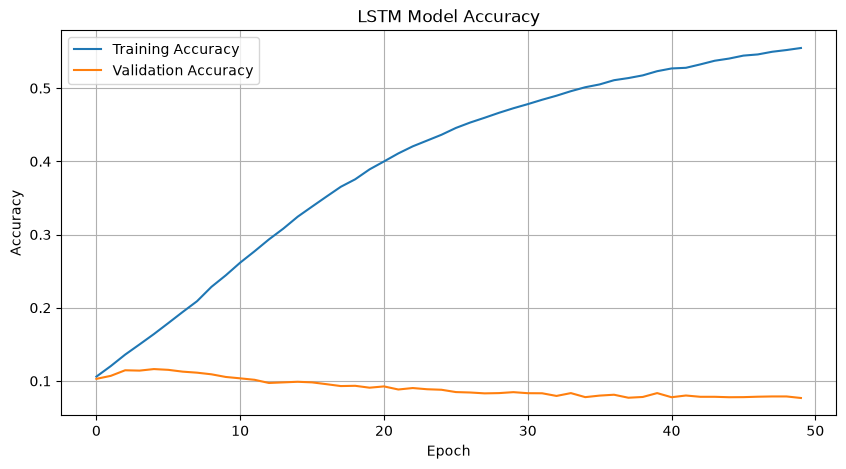

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(history_lstm.history['accuracy'], label='Training Accuracy')
plt.plot(history_lstm.history['val_accuracy'], label='Validation Accuracy')

plt.title('LSTM Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

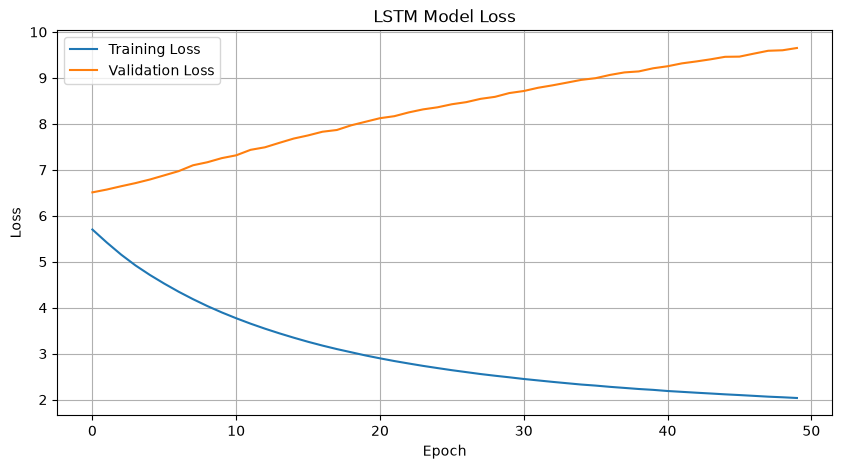

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(history_lstm.history['loss'], label='Training Loss')
plt.plot(history_lstm.history['val_loss'], label='Validation Loss')

plt.title('LSTM Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Load LSTM Model

In [31]:
lstm_model = load_model("lstm_model.h5")

print("LSTM model loaded successfully!")

LSTM model loaded successfully!


# Next Word Prediction

In [32]:
def predict_next_word(seed_text):

    token_list = tokinizer.texts_to_sequences([seed_text])[0]

    token_list = pad_sequences(
        [token_list],
        maxlen=max_len,
        padding='pre',
        truncating='pre'
    )

    predicted = lstm_model.predict(token_list, verbose=0)

    predicted_word_index = np.argmax(predicted, axis=-1)[0]

    for word, index in tokinizer.word_index.items():

        if index == predicted_word_index:
            return word

    return None

In [38]:
seed_text = "the meaning of life"

predicted_word = predict_next_word(seed_text)

print("Input:", seed_text)
print("Predicted next word:", predicted_word)

Input: the meaning of life
Predicted next word: is


# Generate Complete Text

In [39]:
def generate_text(seed_text, next_words=15):

    for _ in range(next_words):

        next_word = predict_next_word(seed_text)

        if next_word is None:
            break

        seed_text += " " + next_word

    return seed_text

In [40]:
print(generate_text(
    "the meaning of life",
    next_words=15
))

the meaning of life is not easy to be what they make your heart happen to youll have to


# Save Tokenizer

In [41]:
import pickle

with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokinizer, file)

print("Tokenizer saved successfully!")

Tokenizer saved successfully!
